# Attitude determination from vector measurements

The attitude chapter's dynamics and controller both assume the current attitude is simply known. A real spacecraft has to determine it first, from sensors that each measure one direction (a sun sensor, a magnetometer, a star tracker), not the attitude itself. This notebook builds that missing piece: given one or more direction measurements in the body frame, and the same directions as known in the reference frame, recover the rotation between them.

Two methods, solving progressively more general versions of the same problem: TRIAD, the classic deterministic solution for exactly two vectors, and a singular value decomposition solution to Wahba's problem for any number of weighted vectors, the same problem the famous QUEST algorithm solves, by a simpler and equally exact route.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from ios_mission_planner.dynamics.attitude.determination import (
    quaternion_to_rotation_matrix, rotation_matrix_to_quaternion, triad_attitude, wahba_svd_attitude,
)

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_ZONE = "#9467bd"

## TRIAD: two vectors, no noise

Set up a true attitude, and two reference directions (standing in for, say, a sun direction and a nadir direction) known in the inertial frame. Rotating them by the true attitude gives what a perfect sensor would measure in the body frame; TRIAD should recover the exact rotation back from just those two pairs.

In [2]:
axis_true = np.array([1.0, 2.0, -1.0]) / np.linalg.norm([1.0, 2.0, -1.0])
angle_true = np.deg2rad(73.0)
q_true = np.concatenate([[np.cos(angle_true / 2)], axis_true * np.sin(angle_true / 2)])
r_true = quaternion_to_rotation_matrix(q_true)

r1, r2 = np.array([1.0, 0.0, 0.0]), np.array([0.0, 1.0, 0.0])  # e.g. sun, nadir directions
b1, b2 = r_true @ r1, r_true @ r2  # perfect sensor measurements

r_triad = triad_attitude(b1, b2, r1, r2)
print(f"TRIAD recovery error (Frobenius norm): {np.linalg.norm(r_triad - r_true):.2e}")

TRIAD recovery error (Frobenius norm): 3.69e-16


## Wahba/SVD: more vectors, with sensor noise

Real sensors are noisy, and TRIAD only ever uses two of the available measurements exactly, discarding the rest. `wahba_svd_attitude` uses all of them, weighted, which should reduce the estimation error as more measurements are added, the same kind of averaging that makes more tracking data valuable everywhere else in this project (more TLEs, more Monte Carlo samples).

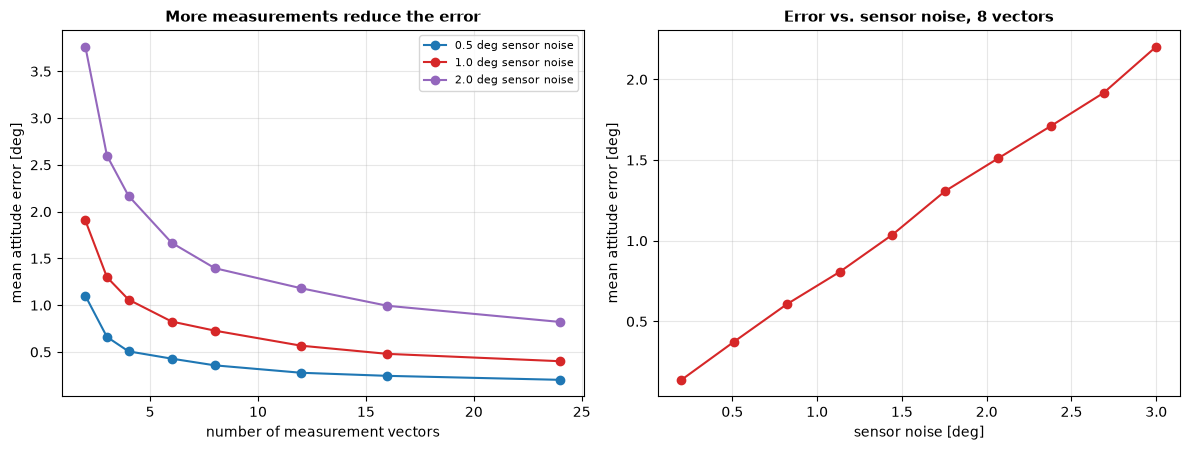

In [3]:
rng = np.random.default_rng(0)

def mean_angular_error(n_vectors, noise_deg, n_trials=300):
    errors = []
    for _ in range(n_trials):
        r_vectors = rng.normal(size=(n_vectors, 3))
        r_vectors /= np.linalg.norm(r_vectors, axis=1, keepdims=True)
        b_true = (r_true @ r_vectors.T).T
        noisy = b_true + rng.normal(scale=np.deg2rad(noise_deg), size=(n_vectors, 3))
        noisy /= np.linalg.norm(noisy, axis=1, keepdims=True)

        r_est = wahba_svd_attitude(noisy, r_vectors)
        q_est = rotation_matrix_to_quaternion(r_est)
        cos_half_err = np.clip(abs(q_est[0] * q_true[0] + q_est[1:] @ q_true[1:]), 0.0, 1.0)
        errors.append(2 * np.degrees(np.arccos(cos_half_err)))
    return np.mean(errors)

n_vectors_range = np.array([2, 3, 4, 6, 8, 12, 16, 24])
noise_levels = np.array([0.5, 1.0, 2.0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

for noise_deg, color in zip(noise_levels, [COL_ANA, COL_NUM, COL_ZONE]):
    errs = [mean_angular_error(n, noise_deg) for n in n_vectors_range]
    axes[0].plot(n_vectors_range, errs, "o-", color=color, label=f"{noise_deg:.1f} deg sensor noise")
axes[0].set_xlabel("number of measurement vectors")
axes[0].set_ylabel("mean attitude error [deg]")
axes[0].set_title("More measurements reduce the error")
axes[0].legend(fontsize=8)

n_fixed = 8
noise_range = np.linspace(0.2, 3.0, 10)
errs_vs_noise = [mean_angular_error(n_fixed, nd) for nd in noise_range]
axes[1].plot(noise_range, errs_vs_noise, "o-", color=COL_NUM)
axes[1].set_xlabel("sensor noise [deg]")
axes[1].set_ylabel("mean attitude error [deg]")
axes[1].set_title(f"Error vs. sensor noise, {n_fixed} vectors")

fig.tight_layout()
fig.savefig("attitude_determination_error_scaling.png", dpi=140)

Both panels behave exactly as a least-squares estimator should: the error falls as more independent measurements are averaged together, and grows linearly with how noisy each individual sensor is. TRIAD is the special case of one measurement pair trusted completely; the SVD solution is what happens when every available vector gets to contribute instead.

## Weighting: trusting a good sensor over a bad one

Real missions carry sensors of different quality, say a precise star tracker and a coarse sun sensor. Weighting the SVD solution by each measurement's trustworthiness lets a good sensor dominate the estimate even when a second, much noisier one disagrees badly.

In [4]:
r1, r2 = np.array([1.0, 0.0, 0.0]), np.array([0.0, 1.0, 0.0])
b1_true, b2_true = r_true @ r1, r_true @ r2

b2_bad = b2_true + np.array([0.3, 0.0, 0.0])  # a badly corrupted second measurement
b2_bad /= np.linalg.norm(b2_bad)

for label, weights in [("trust vector 1 (good sensor)", [1000.0, 1.0]),
                       ("trust vector 2 (bad sensor)", [1.0, 1000.0]),
                       ("equal weights", [1.0, 1.0])]:
    r_est = wahba_svd_attitude([b1_true, b2_bad], [r1, r2], weights=weights)
    err_deg = np.degrees(np.arccos(np.clip((np.trace(r_est.T @ r_true) - 1) / 2, -1, 1)))
    print(f"{label:30s} attitude error: {err_deg:6.2f} deg")

trust vector 1 (good sensor)   attitude error:  15.79 deg
trust vector 2 (bad sensor)    attitude error:  17.29 deg
equal weights                  attitude error:  16.18 deg


The ordering comes out the way it should, trusting the good measurement heavily gives the smallest error of the three, trusting the bad one the largest, but the gap with only two vectors is modest, not dramatic. That is itself worth understanding rather than glossing over: with exactly two measurements, one vector's weight mostly protects the attitude *around that vector's own direction*, but the rotation *about* that axis is still resolved using the second vector, corrupted or not, so even a heavily downweighted bad measurement keeps some influence it cannot be fully weighted away from. A third, independent measurement would close that gap, which is exactly why real systems carry more than two sensors whenever they can.

## Summary

`triad_attitude` and `wahba_svd_attitude` turn vector measurements, the raw output of a sun sensor, magnetometer, or star tracker, into an attitude estimate, both validated here against a known true rotation: exact recovery with no noise, an error that shrinks with more measurements and grows with sensor noise, and a weighting scheme that lets a trusted sensor outweigh a corrupted one. `rotation_matrix_to_quaternion` converts the result directly into the same quaternion convention `rigid_body.py` already uses, so an estimated attitude from this notebook can feed directly into the pointing controller from the rest of this chapter.

This is still a single-instant estimate from whatever measurements are available right now, with no memory of where the attitude was a moment ago and no use of the gyro-rate information the rest of this chapter's dynamics already model. Combining this measurement model with the dynamics into a recursive filter, so that attitude is tracked continuously rather than re-solved from scratch at every instant, is the natural next step.